## 1. Data Understanding

### Dataset Description

The SECOM dataset contains measurements collected
from a semiconductor manufacturing process.

The objective is to investigate whether manufacturing
measurements can help predict product quality failures.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Dataset paths
DATA_DIR = Path("../secom_data/raw")

data_path = DATA_DIR / "secom.data"
labels_path = DATA_DIR / "secom_labels.data"

# Load data
X_raw = pd.read_csv(data_path, delimiter="\s+", header=None)
y_raw = pd.read_csv(labels_path, delimiter="\s+", header=None)

y = y_raw.iloc[:,0]

print("Feature dimensions:", X_raw.shape)
print("Target dimensions:", y.shape)

print("Number of observations:", X_raw.shape[0])
print("Number of features:", X_raw.shape[1])

# Missing values per feature
missing_values = X_raw.isnull().sum()

# Total missing values
print(missing_values.sum())

# Features containing missing values
print(
    "Features with missing values:",
    (missing_values > 0).sum()
)

# Percentage of missing values
missing_percentage = (
    X_raw.isnull().sum().sum()*100/ X_raw.size
)

print("Missing value percentage:",missing_percentage)
print("Duplicate rows:", X_raw.duplicated().sum())

Feature dimensions: (1567, 590)
Target dimensions: (1567,)
Number of observations: 1567
Number of features: 590
41951
Features with missing values: 538
Missing value percentage: 4.537548808583821
Duplicate rows: 0


In [2]:
missing_summary = pd.DataFrame({
    "missing_count": X_raw.isnull().sum(),
    "missing_percentage": X_raw.isnull().mean() * 100
})

# Sort features from highest to lowest missing percentage
missing_summary = missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)


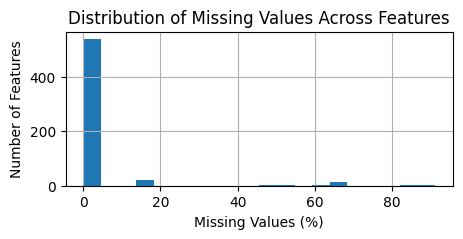

In [ ]:
import matplotlib.pyplot as plt

missing_summary["missing_percentage"].plot(
    kind="hist",
    bins=20,
    grid=True,
    figsize=(5, 2)
)

plt.title("Distribution of Missing Values Across Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Number of Features")
plt.show()

In [ ]:
# Count each quality outcome
print("Target distribution:")
print(y.value_counts().sort_index())

# Calculate percentages
print("\nTarget distribution (%):")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Target distribution:
0
-1    1463
 1     104
Name: count, dtype: int64

Target distribution (%):
0
-1    93.36
 1     6.64
Name: proportion, dtype: float64


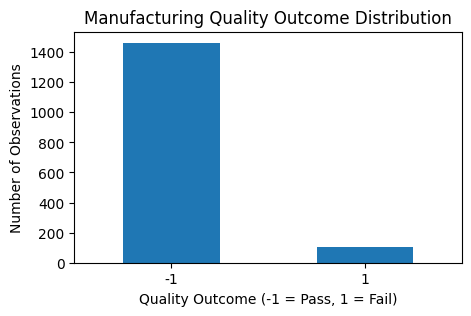

In [ ]:
y.value_counts().sort_index().plot(
    kind="bar",
    figsize=(5, 3)
)

plt.title("SECOM Manufacturing Quality Outcome Distribution")
plt.xlabel("Quality Outcome (-1 = Pass, 1 = Fail)")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

## Summary

### Input features:

- Total features: 590
- Total observations: 1568
- Overall missing value percentage: 4.54% of all data values
- 538 features out of totl 590 have atleast one missing value
- 41951 data values are missing across 538 features
- No duplicates found at row level

### Target values:
- Quality test passed percentage: 93.36
- Quality test failed percentage: 6.64
- This indicates a significant class imbalance: 
    This imbalance presents a challenge for predictive modelling, as a classifier may achieve high overall accuracy while failing to identify manufacturing defects. Therefore, model evaluation needs to have an emphasis on failure-class precision, recall, F1-score and Precision-Recall AUC rather than relying on accuracy alone.